# Week 11: Geocodes and layering
***Name***: Isabelle Sakelaris \
***Date***: November 9, 2026

Geocoding is translating from a place name ("Pratt Institute School of Information") to longitue and latitude. We can use [OpenStreetMap](https://www.openstreetmap.org/#map=4/38.01/-95.84) for this, which is community maintained. It is a website and they also have an API.

In [1]:
import json
import time

import pandas as pd
import plotly.express as px
import requests

In [3]:
url = "https://nominatim.openstreetmap.org/search" # the api url

# an honest name for our program, as in Part 11. Nominatim blocks requests without one!
headers = {"User-Agent": "INFO664-class-project (educational)"}

params = {"q": "Pratt Institute, Brooklyn", "format": "jsonv2", "limit": 1} # will pass the parameters as a dictionary, with a limit of one result.

#results will be sorted by relevance

response = requests.get(url, params=params, headers=headers)

# check that the request worked (200 means OK), and look at the address that requests built.
print(response.status_code)
print(response.url)

200
https://nominatim.openstreetmap.org/search?q=Pratt+Institute%2C+Brooklyn&format=jsonv2&limit=1


In [5]:
results = response.json()
print(len(results), "result")
print(json.dumps(results[0], indent=2)) # dumps with indent prints json in a readable way
# note that we need to specify the first result bc they come back in a list

1 result
{
  "place_id": 359030172,
  "licence": "Data \u00a9 OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright",
  "osm_type": "relation",
  "osm_id": 4425764,
  "lat": "40.6913383",
  "lon": "-73.9630163",
  "category": "amenity",
  "type": "university",
  "place_rank": 30,
  "importance": 0.5429685502967774,
  "addresstype": "amenity",
  "name": "Pratt Institute",
  "display_name": "Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States",
  "boundingbox": [
    "40.6877108",
    "40.6945682",
    "-73.9682790",
    "-73.9604328"
  ]
}


Make sure to look at the keys. We want `lat` and `lon`. We also need to change the lat and long from strings to numbers using `float`

In [9]:
place = results[0]
latitude = float(place["lat"])
longitude = float(place["lon"])

print(place["display_name"])
print(latitude, longitude)

Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States
40.6913383 -73.9630163


### Useful function
Takes a string as an argument and outputs informaition in a dictionary!

In [10]:
def geocode(query):
    """Look up a place name or address. Return a dictionary with its coordinates, or None."""
    params = {"q": query, "format": "jsonv2", "limit": 1}
    response = requests.get(url, params=params, headers=headers)

    time.sleep(1)                  # be polite: no more than one request per second

    if not response.ok:            # for example, a 403 or 429 error
        print("request failed:", response.status_code, "for", query)
        return None

    results = response.json()

    if len(results) == 0:          # nothing matched
        print("no match for:", query)
        return None

    place = results[0]

    return {
        "query": query,
        "name": place["name"],
        "address": place["display_name"],
        "type": place["type"],
        "lat": float(place["lat"]),
        "lon": float(place["lon"]),
    }


geocode("Brooklyn Museum")

{'query': 'Brooklyn Museum',
 'name': 'Brooklyn Museum',
 'address': 'Brooklyn Museum, 200, Eastern Parkway, Brooklyn, Kings County, New York, 11238, United States',
 'type': 'museum',
 'lat': 40.6709546,
 'lon': -73.9632948}

In [14]:
queries = [
    "Pratt Institute, Brooklyn",
    "Brooklyn Museum",
    "Metropolitan Museum of Art, New York",
    "Cooper Hewitt, New York",
    "Guggenheim Museum, New York",
    "Whitney Museum of American Art",
    "qwertyuiop zxcvbnm nowhere",
]

places = []

for query in queries:
    result = geocode(query)

    if result is not None:
        places.append(result)

print(len(places), "of", len(queries), "found")

no match for: qwertyuiop zxcvbnm nowhere
6 of 7 found


In [16]:
table = pd.DataFrame(places)
table[["query", "name", "type", "lat", "lon"]]

,query,name,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,museum,40.782993,-73.958925
5,Whitney Museum of American Art,Whitney Museum of American Art,museum,40.739645,-74.008921


### Using them with maps
`px.scatter_map()` draws a dot at each latitude and longitude, using the same background maps as the choropleth maps in Week 10.

Unlike the Week 10 maps, we have to tell it "where to point the camera." If we leave out **center**, Plotly starts at latitude 0, longitude 0, which is open ocean, so the map looks empty. The middle of our places is the **average** of their latitudes and longitudes.

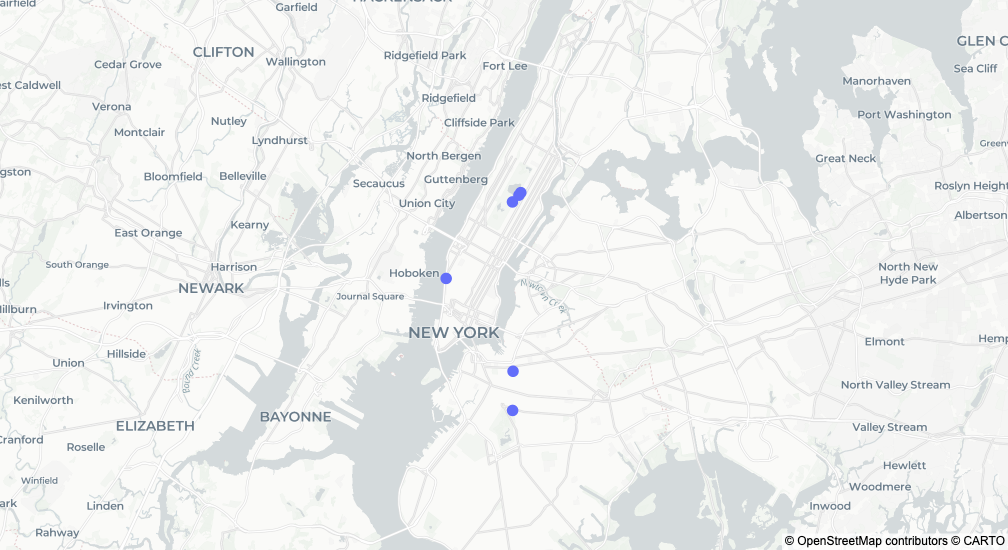

In [18]:
# the center of the map: the average latitude and the average longitude of our places
center = {"lat": table["lat"].mean(), "lon": table["lon"].mean()}

fig = px.scatter_map(
    table,
    lat="lat",                           # the columns with each place's coordinates
    lon="lon",
    hover_name="name",
    hover_data={"address": True, "lat": False, "lon": False},
    center=center,                       # where the map is centered at first
    zoom=10,                             # how far in: a bigger number is closer
    height=550,
)

fig.update_traces(marker={"size": 12})
fig.update_layout(map_style="carto-positron", margin={"l": 0, "r": 0, "t": 0, "b": 0})

fig.show()

### Saving
So we don't have to do this multiple times

In [19]:
table.to_csv("geocoded_places.csv", index=False)

pd.read_csv("geocoded_places.csv").head()

,query,name,address,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,"Pratt Institute, 200, Willoughby Avenue, Clint...",university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,"Brooklyn Museum, 200, Eastern Parkway, Brookly...",museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,"The Metropolitan Museum of Art, 1000, 5th Aven...",museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum","Cooper–Hewitt, Smithsonian Design Museum, 2, E...",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,"Guggenheim Museum, 1071, 5th Avenue, Carnegie ...",museum,40.782993,-73.958925


### Doing it in reverse!

In [20]:
reverse_params = {"lat": 40.6913, "lon": -73.9630, "format": "jsonv2"}

response = requests.get("https://nominatim.openstreetmap.org/reverse", params=reverse_params, headers=headers)

print(response.json()["display_name"])

200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States
